# Chapter 4 — Training Models: Practice Notebook

In this notebook, we explore how machine learning models train and find optimal parameters under the hood, beginning with **Linear Regression** and direct analytical solutions.

## 1. Linear Regression: Generating Linear Synthetic Data

Let's generate random linear data using the function:
$$y = 4 + 3x + \text{Gaussian noise}$$

Here:
- True $\theta_0 = 4$ (bias / intercept)
- True $\theta_1 = 3$ (slope / feature weight)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducible results
np.random.seed(42)

# Generate 100 random instances with 1 feature (x1 in range [0, 2))
X = 2 * np.random.rand(100, 1)

# Target: y = 4 + 3x + Gaussian noise (mean 0, std 1)
y = 4 + 3 * X + np.random.randn(100, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 1)
y shape: (100, 1)


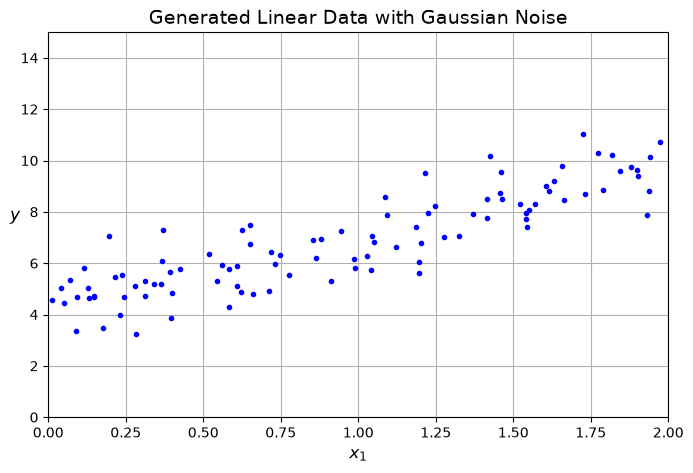

In [2]:
# Visualize the generated synthetic dataset
plt.figure(figsize=(8, 5))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=12)
plt.ylabel("$y$", rotation=0, fontsize=12)
plt.title("Generated Linear Data with Gaussian Noise", fontsize=14)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()

## 2. Solving with the Normal Equation

The **Normal Equation** directly computes the parameter vector $\hat{\mathbf{\theta}}$ that minimizes the Mean Squared Error (MSE):
$$\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

To include the bias term $\theta_0$, we must add a column of ones ($x_0 = 1$) to each instance using `np.c_`.

In [3]:
# Add x0 = 1 to each instance (shape becomes 100 x 2)
X_b = np.c_[np.ones((100, 1)), X]

# Compute optimal theta using the Normal Equation: (X^T . X)^(-1) . X^T . y
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Estimated theta_0 (Intercept):", theta_best[0][0])
print("Estimated theta_1 (Slope):    ", theta_best[1][0])
print("\nNotice: The true function was y = 4 + 3x. Due to the added noise, our estimates are close (~4.215 and ~2.770)!")

Estimated theta_0 (Intercept): 4.21509615754675
Estimated theta_1 (Slope):     2.7701133864384806

Notice: The true function was y = 4 + 3x. Due to the added noise, our estimates are close (~4.215 and ~2.770)!


Predictions on x1=0 and x1=2:
 [[4.21509616]
 [9.75532293]]


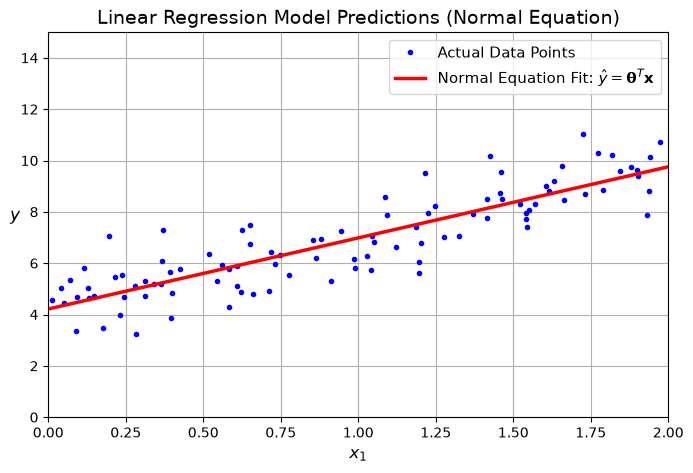

In [4]:
# Make predictions using the fitted theta on new points: x1 = 0 and x1 = 2
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]  # add x0 = 1
y_predict = X_new_b @ theta_best
print("Predictions on x1=0 and x1=2:\n", y_predict)

# Plot the predictions line against the actual data
plt.figure(figsize=(8, 5))
plt.plot(X, y, "b.", label="Actual Data Points")
plt.plot(X_new, y_predict, "r-", linewidth=2.5, label="Normal Equation Fit: $\\hat{y} = \\mathbf{\\theta}^T \\mathbf{x}$")
plt.xlabel("$x_1$", fontsize=12)
plt.ylabel("$y$", rotation=0, fontsize=12)
plt.title("Linear Regression Model Predictions (Normal Equation)", fontsize=14)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend(fontsize=11)
plt.show()

## 3. Scikit-Learn's `LinearRegression` (SVD Pseudoinverse)

Scikit-Learn provides `LinearRegression`, which solves the problem using the **Moore-Penrose Pseudoinverse** via **Singular Value Decomposition (SVD)**:
$$\hat{\mathbf{\theta}} = \mathbf{X}^+ \mathbf{y}$$

This avoids directly inverting $\mathbf{X}^T \mathbf{X}$, making it faster ($\approx \mathcal{O}(n^2)$ instead of $\mathcal{O}(n^3)$) and numerically stable even if features are collinear.

In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Scikit-Learn Intercept (theta_0):", lin_reg.intercept_)
print("Scikit-Learn Slope (theta_1):    ", lin_reg.coef_)

# Verify predictions match the Normal Equation
print("\nPredictions via lin_reg.predict(X_new):\n", lin_reg.predict(X_new))

Scikit-Learn Intercept (theta_0): [4.21509616]
Scikit-Learn Slope (theta_1):     [[2.77011339]]

Predictions via lin_reg.predict(X_new):
 [[4.21509616]
 [9.75532293]]


In [6]:
# Computing pseudoinverse directly with NumPy: theta = X+ @ y
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
print("Theta via np.linalg.lstsq:\n", theta_best_svd)

# Or via np.linalg.pinv:
theta_pinv = np.linalg.pinv(X_b) @ y
print("\nTheta via np.linalg.pinv:\n", theta_pinv)

Theta via np.linalg.lstsq:
 [[4.21509616]
 [2.77011339]]

Theta via np.linalg.pinv:
 [[4.21509616]
 [2.77011339]]


### Summary Comparison: Normal Equation vs. Scikit-Learn SVD
- Both methods yield the exact same parameters ($\theta_0 \approx 4.215, \theta_1 \approx 2.770$).
- `LinearRegression` uses `scipy.linalg.lstsq()` (SVD pseudoinverse), which handles singular/collinear matrices seamlessly.
- Both methods require storing the full dataset in memory (no streaming) and scale poorly as the number of features $n$ grows large $\implies$ motivating **Gradient Descent**!